# Transfer Learning

Transfer Learning is the process of reusing knowledge and pre-trained models developed for one task to solve a different but related task. This approach allows for rapid training and high performance on new datasets, even with limited data.

## Flower Classification using MobileNetV2

In this project, we utilize **MobileNetV2** to classify flowers into 102 different categories using the Oxford Flowers 102 dataset.

In [4]:
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import torchvision.datasets as datasets
import torchvision.models as models
from torch.utils.data import DataLoader
from tqdm import tqdm
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

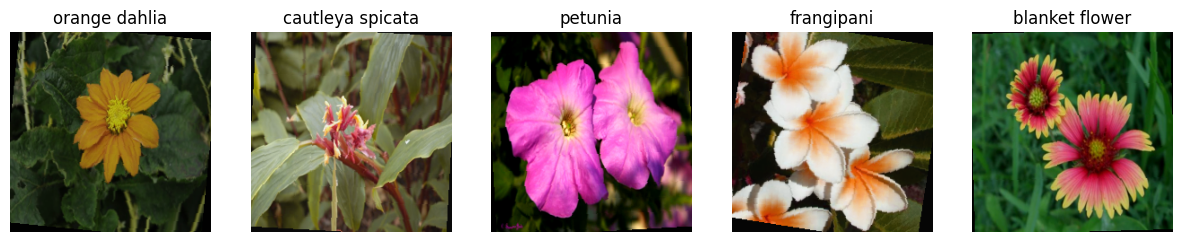

/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=MobileNet_V2_Weights.IMAGENET1K_V1`. You can also use `weights=MobileNet_V2_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)
 33%|███▎      | 1/3 [00:17<00:35, 17.83s/it]

Epoch 1/3, Loss: 4.5895



 67%|██████▋   | 2/3 [00:34<00:17, 17.31s/it]

Epoch 2/3, Loss: 2.9752



100%|██████████| 3/3 [00:51<00:00, 17.27s/it]

Epoch 3/3, Loss: 2.0247


In [5]:
# Data loading and data augmentation
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Data transformations
# 1 Standard transformations: normalization, tensor conversion
# 2 Resize input to match MobileNet requirements
# 3 Data augmentation

transform_train = transforms.Compose([
    transforms.Resize((224, 224)), # MobileNet input size
    transforms.RandomHorizontalFlip(), # Horizontal flip for data augmentation
    transforms.RandomRotation(10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.1),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

transform_test = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

# Load Oxford Flowers 102 dataset
train_dataset = datasets.Flowers102(root='./data', split='train', download=True, transform=transform_train)
test_dataset = datasets.Flowers102(root='./data', split='val', download=True, transform=transform_test)

# Select 5 random samples
indices = torch.randint(len(train_dataset), (5,))
samples = [train_dataset[i] for i in indices]

# Visualization
fig, axes = plt.subplots(1, 5, figsize=(15, 5))
for i, (image, label) in enumerate(samples):
    image = image.numpy().transpose((1, 2, 0)) # Convert tensor to image format
    image = (image * 0.5) + 0.5 # Revert normalization
    axes[i].imshow(image)
    axes[i].set_title(train_dataset.classes[label])
    axes[i].axis('off')
plt.show()

# Data loaders
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

# Define transfer learning, fine-tuning, and model saving

# Load MobileNetV2
model = models.mobilenet_v2(pretrained=True) # Use pre-trained weights

# Add classifier layer
number_ftrs = model.classifier[1].in_features # Get input features of the current classifier
model.classifier[1] = nn.Linear(number_ftrs, 102) # Modify the final layer for Oxford Flowers 102
model = model.to(device)

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # For multi-class classification
optimizer = optim.Adam(model.classifier[1].parameters(), lr=0.001)
scheduler = optim.lr_scheduler.StepLR(optimizer, step_size=5, gamma=0.1) # Step learning rate scheduler

# Model training
epochs = 3
for epoch in tqdm(range(epochs)):
    model.train() # Set model to training mode
    running_loss = 0.0 # Total loss value
    for images, labels in tqdm(train_loader):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad() # Reset gradients from previous step
        outputs = model(images) # Model forward pass
        loss = criterion(outputs, labels) # Calculate loss
        loss.backward() # Backward pass to compute gradients
        optimizer.step() # Update weights
        running_loss += loss.item() # Accumulate loss
    scheduler.step() # Update learning rate
    print(f"Epoch {epoch+1}/{epochs}, Loss: {running_loss/len(train_loader):.4f}")

# Save model
torch.save(model.state_dict(), 'mobilenet_v1_flowers102.pth')

100%|██████████| 32/32 [00:09<00:00,  3.26it/s]


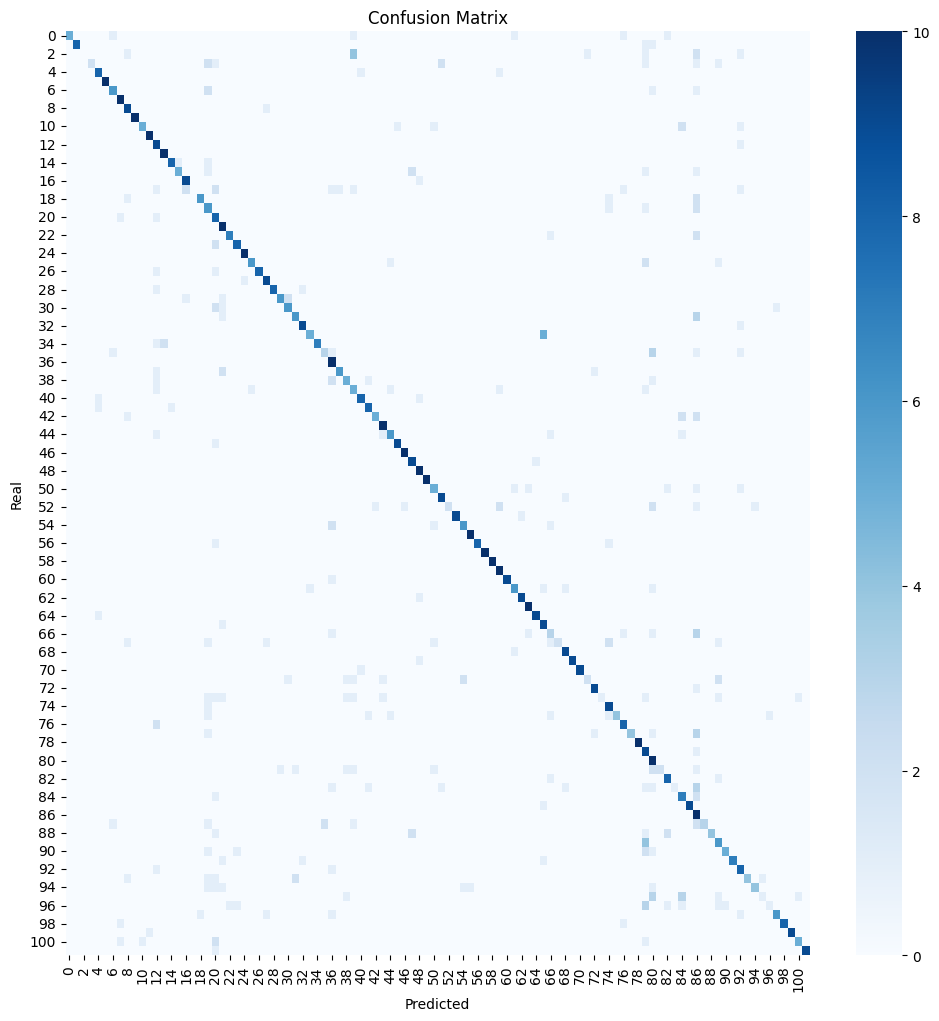

              precision    recall  f1-score   support

           0       1.00      0.50      0.67        10
           1       1.00      0.80      0.89        10
           2       0.00      0.00      0.00        10
           3       1.00      0.20      0.33        10
           4       0.73      0.80      0.76        10
           5       1.00      1.00      1.00        10
           6       0.67      0.60      0.63        10
           7       0.77      1.00      0.87        10
           8       0.64      0.90      0.75        10
           9       1.00      1.00      1.00        10
          10       0.83      0.50      0.62        10
          11       0.91      1.00      0.95        10
          12       0.43      0.90      0.58        10
          13       0.83      1.00      0.91        10
          14       0.89      0.80      0.84        10
          15       0.83      0.50      0.62        10
          16       0.75      0.90      0.82        10
          17       0.00    

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [7]:
# Testing and evaluation
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
  for images, labels in tqdm(test_loader):
    images, labels = images.to(device), labels.to(device)
    outputs = model(images)
    _, predicted = torch.max(outputs, 1)
    all_preds.extend(predicted.cpu().numpy())
    all_labels.extend(labels.cpu().numpy())

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12, 12))
sns.heatmap(cm, annot=False, cmap="Blues")
plt.xlabel("Predicted")
plt.ylabel("Real")
plt.title("Confusion Matrix")
plt.show()

# Classification report
print(classification_report(all_labels, all_preds))